In [28]:
import pandas as pd
import numpy as np
from garminconnect import (
    Garmin,
    GarminConnectAuthenticationError,
    GarminConnectConnectionError,
)
from datetime import date, timedelta
from datetime import date, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.widgets import CheckButtons


### Connceting

In [29]:
import os
from getpass import getpass

# Credentials come from environment variables, never hard-code them
email = os.environ.get("GARMIN_EMAIL") or input("Garmin email: ")
password = os.environ.get("GARMIN_PASSWORD") or getpass("Garmin password: ")

try:
    client = Garmin(email, password)
    client.login()
except (GarminConnectConnectionError, GarminConnectAuthenticationError) as e:
    print(f"Error connecting: {e}")

### Sleep

In [15]:
# ----------------------------------------------------
# איסוף נתוני שינה מהשנה האחרונה
# ----------------------------------------------------
end_date = date.today()
start_date = end_date - timedelta(days=365)
date_range = pd.date_range(start=start_date, end=end_date)

sleep_records = []
print("Fetching sleep data for the past year...")

for dt in date_range:
    date_str = dt.strftime("%Y-%m-%d")
    try:
        data = client.get_sleep_data(date_str)
        dto = data.get("dailySleepDTO", {})

        # סינון לילות שבהם אין נתונים
        if dto and dto.get("sleepTimeSeconds", 0) > 0:
            sleep_records.append(
                {
                    "date": date_str,
                    "total_sleep_hours": dto.get("sleepTimeSeconds", 0) / 3600,
                    "rem_sleep_hours": dto.get("remSleepSeconds", 0) / 3600,
                }
            )
    except Exception:
        continue

if not sleep_records:
    raise ValueError("No valid sleep data retrieved.")

df_sleep = pd.DataFrame(sleep_records)
df_sleep["date"] = pd.to_datetime(df_sleep["date"])
df_sleep.sort_values("date", inplace=True)
df_sleep.set_index("date", inplace=True)


Fetching sleep data for the past year...


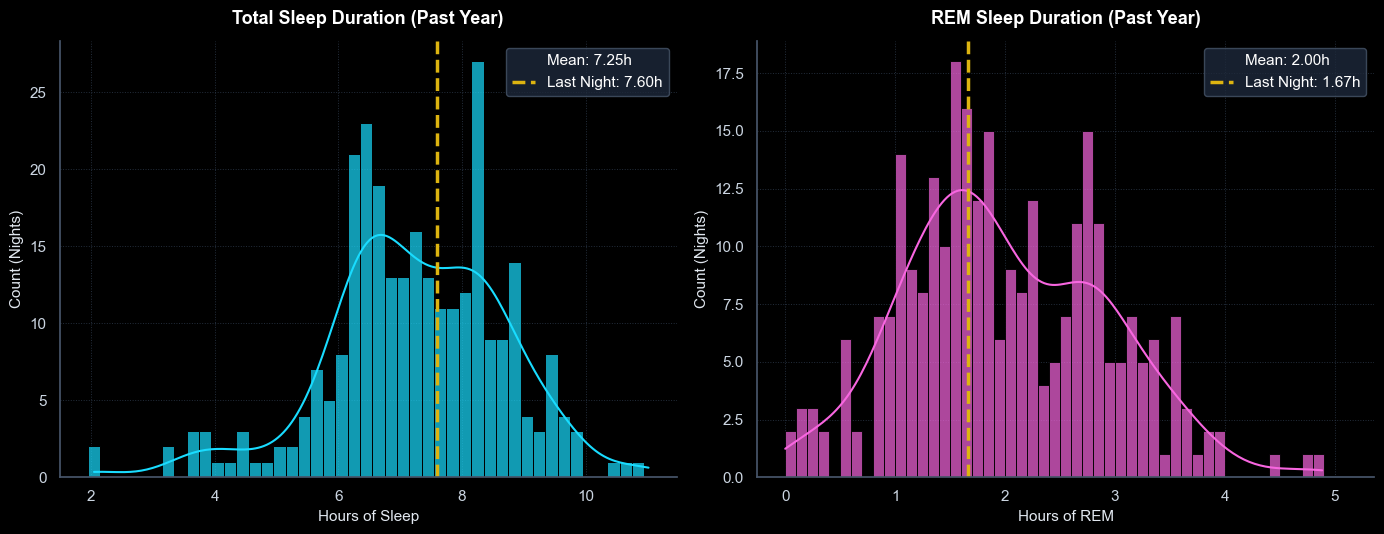

In [35]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# חילוץ ערכי הלילה האחרון וממוצעים
latest_row = df_sleep.sort_index().iloc[-1]
latest_date_str = latest_row.name.strftime("%Y-%m-%d")
latest_total = latest_row["total_sleep_hours"]
latest_rem = latest_row["rem_sleep_hours"]

mean_total = df_sleep["total_sleep_hours"].mean()
mean_rem = df_sleep["rem_sleep_hours"].mean()

# הגדרת תמת Dark Mode
plt.style.use("dark_background")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), facecolor="black")

# פלטת צבעים מותאמת
total_color = "#19dcff"
rem_color = "#f866e0"
highlight_color = "#ddb410"

# ----------------------------------------------------
# 1. היסטוגרמה: סך שעות שינה
# ----------------------------------------------------
sns.histplot(
    data=df_sleep,
    x="total_sleep_hours",
    kde=True,
    bins=np.arange(df_sleep["total_sleep_hours"].min() - 0.1, df_sleep["total_sleep_hours"].max() + 0.1, 0.2),
    color=total_color,
    edgecolor="black",
    alpha=0.7,
    ax=axes[0],
)

axes[0].set_facecolor("black")
axes[0].set_title(
    "Total Sleep Duration (Past Year)",
    fontsize=13,
    weight="bold",
    color="white",
    pad=12,
)
axes[0].set_xlabel("Hours of Sleep", fontsize=11, color="#e2e8f0")
axes[0].set_ylabel("Count (Nights)", fontsize=11, color="#e2e8f0")
axes[0].tick_params(colors="#cbd5e1")
axes[0].grid(color="#334155", linestyle=":", linewidth=0.7, alpha=0.7)

# סימון הלילה האחרון (צהוב)
axes[0].axvline(
    latest_total,
    color=highlight_color,
    linestyle="--",
    linewidth=2.5,
    label=f"Last Night: {latest_total:.2f}h",
)

# הוספת הממוצע למקרא בלבד
handles_0, labels_0 = axes[0].get_legend_handles_labels()
mean_handle_0 = mlines.Line2D([], [], color="none", label=f"Mean: {mean_total:.2f}h")
handles_0.insert(0, mean_handle_0)

axes[0].legend(
    handles=handles_0,
    facecolor="#1e293b",
    edgecolor="#475569",
    labelcolor="white",
    handlelength=1.5,
)

# ----------------------------------------------------
# 2. היסטוגרמה: שעות REM
# ----------------------------------------------------
sns.histplot(
    data=df_sleep,
    x="rem_sleep_hours",
    kde=True,
    bins=np.arange(0, df_sleep["rem_sleep_hours"].max() + 0.25, 0.1),
    color=rem_color,
    edgecolor="black",
    alpha=0.7,
    ax=axes[1],
)

axes[1].set_facecolor("black")
axes[1].set_title(
    "REM Sleep Duration (Past Year)",
    fontsize=13,
    weight="bold",
    color="white",
    pad=12,
)
axes[1].set_xlabel("Hours of REM", fontsize=11, color="#e2e8f0")
axes[1].set_ylabel("Count (Nights)", fontsize=11, color="#e2e8f0")
axes[1].tick_params(colors="#cbd5e1")
axes[1].grid(color="#334155", linestyle=":", linewidth=0.7, alpha=0.7)

# סימון הלילה האחרון (צהוב)
axes[1].axvline(
    latest_rem,
    color=highlight_color,
    linestyle="--",
    linewidth=2.5,
    label=f"Last Night: {latest_rem:.2f}h",
)

# הוספת הממוצע למקרא בלבד
handles_1, labels_1 = axes[1].get_legend_handles_labels()
mean_handle_1 = mlines.Line2D([], [], color="none", label=f"Mean: {mean_rem:.2f}h")
handles_1.insert(0, mean_handle_1)

axes[1].legend(
    handles=handles_1,
    facecolor="#1e293b",
    edgecolor="#475569",
    labelcolor="white",
    handlelength=1.5,
)

# הסרת מסגרות עליונות וימניות
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#475569")
    ax.spines["bottom"].set_color("#475569")

plt.tight_layout()
plt.show()

In [39]:
from datetime import date, timedelta
import tkinter as tk
from tkinter import ttk
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ----------------------------------------------------------------------
# 0. הגדרות סגנון ופלטה (Dark Mode אחיד)
# ----------------------------------------------------------------------
plt.style.use("dark_background")

BG_COLOR = "black"
PANEL_BG = "black"
SPINE_COLOR = "#475569"
GRID_COLOR = "#334155"
TEXT_COLOR = "#e2e8f0"
TICK_COLOR = "#cbd5e1"
HIGHLIGHT_COLOR = "#ddb410"  # צהוב זרחני לערך האחרון

END_DATE = date.today()
START_DATE = END_DATE - timedelta(days=365)
DATE_RANGE = pd.date_range(start=START_DATE, end=END_DATE)


def style_axis(ax, title, xlabel, ylabel="Count (Nights)"):
    """פונקציית עזר לעיצוב אחיד של הצירים."""
    ax.set_facecolor(PANEL_BG)
    ax.set_title(title, fontsize=12, weight="bold", color="white", pad=12)
    ax.set_xlabel(xlabel, fontsize=10, color=TEXT_COLOR)
    ax.set_ylabel(ylabel, fontsize=10, color=TEXT_COLOR)
    ax.tick_params(colors=TICK_COLOR)
    ax.grid(color=GRID_COLOR, linestyle=":", linewidth=0.7, alpha=0.7)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(SPINE_COLOR)
    ax.spines["bottom"].set_color(SPINE_COLOR)


# ----------------------------------------------------------------------
# 1. ניתוח שינה (Sleep Duration & REM)
# ----------------------------------------------------------------------
def analyze_sleep(client):
    sleep_records = []
    print("מושך נתוני שינה...")

    for dt in DATE_RANGE:
        date_str = dt.strftime("%Y-%m-%d")
        try:
            data = client.get_sleep_data(date_str)
            dto = data.get("dailySleepDTO", {})
            if dto and dto.get("sleepTimeSeconds", 0) > 0:
                sleep_records.append(
                    {
                        "date": date_str,
                        "total_sleep_hours": dto.get("sleepTimeSeconds", 0)
                        / 3600,
                        "rem_sleep_hours": dto.get("remSleepSeconds", 0) / 3600,
                    }
                )
        except Exception:
            continue

    if not sleep_records:
        print("לא נמצאו נתוני שינה תקינים.")
        return

    df = pd.DataFrame(sleep_records)
    df["date"] = pd.to_datetime(df["date"])
    df.sort_values("date", inplace=True)
    df.set_index("date", inplace=True)

    latest_row = df.iloc[-1]
    latest_total, latest_rem = (
        latest_row["total_sleep_hours"],
        latest_row["rem_sleep_hours"],
    )
    mean_total, mean_rem = (
        df["total_sleep_hours"].mean(),
        df["rem_sleep_hours"].mean(),
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), facecolor=BG_COLOR)

    # 1.1 סך שעות שינה
    bins_total = np.arange(
        df["total_sleep_hours"].min() - 0.1,
        df["total_sleep_hours"].max() + 0.1,
        0.2,
    )
    sns.histplot(
        data=df,
        x="total_sleep_hours",
        kde=True,
        bins=bins_total,
        color="#19dcff",
        edgecolor="black",
        alpha=0.7,
        ax=axes[0],
    )
    style_axis(axes[0], "Total Sleep Duration (Past Year)", "Hours of Sleep")
    axes[0].axvline(
        latest_total,
        color=HIGHLIGHT_COLOR,
        linestyle="--",
        linewidth=2.5,
        label=f"Last Night: {latest_total:.2f}h",
    )

    h0, l0 = axes[0].get_legend_handles_labels()
    h0.insert(
        0, mlines.Line2D([], [], color="none", label=f"Mean: {mean_total:.2f}h")
    )
    axes[0].legend(
        handles=h0,
        facecolor="#1e293b",
        edgecolor="#475569",
        labelcolor="white",
    )

    # 1.2 שעות REM
    bins_rem = np.arange(0, df["rem_sleep_hours"].max() + 0.25, 0.1)
    sns.histplot(
        data=df,
        x="rem_sleep_hours",
        kde=True,
        bins=bins_rem,
        color="#f866e0",
        edgecolor="black",
        alpha=0.7,
        ax=axes[1],
    )
    style_axis(axes[1], "REM Sleep Duration (Past Year)", "Hours of REM")
    axes[1].axvline(
        latest_rem,
        color=HIGHLIGHT_COLOR,
        linestyle="--",
        linewidth=2.5,
        label=f"Last Night: {latest_rem:.2f}h",
    )

    h1, l1 = axes[1].get_legend_handles_labels()
    h1.insert(
        0, mlines.Line2D([], [], color="none", label=f"Mean: {mean_rem:.2f}h")
    )
    axes[1].legend(
        handles=h1,
        facecolor="#1e293b",
        edgecolor="#475569",
        labelcolor="white",
    )

    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------------------
# 2. ניתוח HRV (Last Night Average vs Nightly Max)
# ----------------------------------------------------------------------
def analyze_hrv(client):
    hrv_records = []
    print("מושך נתוני HRV...")

    for dt in DATE_RANGE:
        date_str = dt.strftime("%Y-%m-%d")
        try:
            data = client.get_hrv_data(date_str)
            summary = data.get("hrvSummary", {})
            weekly_avg = summary.get("weeklyAvg")
            last_night_avg = summary.get("lastNightAvg")

            # בדיקה שקיימים נתוני ממוצע ללילה
            if last_night_avg and last_night_avg > 0:
                hrv_records.append(
                    {
                        "date": date_str,
                        "last_night_avg": float(last_night_avg),
                        "nightly_max": float(
                            summary.get("lastNight5MinHigh", np.nan)
                        ),
                    }
                )
        except Exception:
            continue

    if not hrv_records:
        print("לא נמצאו נתוני HRV תקינים.")
        return

    df = pd.DataFrame(hrv_records)
    df["date"] = pd.to_datetime(df["date"])
    df.sort_values("date", inplace=True)
    df.set_index("date", inplace=True)

    latest_row = df.iloc[-1]
    latest_avg, latest_max = (
        latest_row["last_night_avg"],
        latest_row["nightly_max"],
    )
    mean_avg, mean_max = (
        df["last_night_avg"].mean(),
        df["nightly_max"].dropna().mean(),
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), facecolor=BG_COLOR)

    # 2.1 HRV ממוצע לילי
    bins_avg = np.arange(
        df["last_night_avg"].min() - 2, df["last_night_avg"].max() + 3, 2
    )
    sns.histplot(
        data=df,
        x="last_night_avg",
        kde=True,
        bins=bins_avg,
        color="#38bdf8",
        edgecolor="black",
        alpha=0.7,
        ax=axes[0],
    )
    style_axis(axes[0], "Overnight HRV Average (Past Year)", "rMSSD (ms)")
    axes[0].axvline(
        latest_avg,
        color=HIGHLIGHT_COLOR,
        linestyle="--",
        linewidth=2.5,
        label=f"Last Night: {latest_avg:.1f}ms",
    )

    h0, l0 = axes[0].get_legend_handles_labels()
    h0.insert(
        0, mlines.Line2D([], [], color="none", label=f"Mean: {mean_avg:.1f}ms")
    )
    axes[0].legend(
        handles=h0,
        facecolor="#1e293b",
        edgecolor="#475569",
        labelcolor="white",
    )

    # 2.2 HRV שיא לילי (5-Min Max)
    valid_max_df = df.dropna(subset=["nightly_max"])
    bins_max = np.arange(
        valid_max_df["nightly_max"].min() - 2,
        valid_max_df["nightly_max"].max() + 3,
        2,
    )
    sns.histplot(
        data=valid_max_df,
        x="nightly_max",
        kde=True,
        bins=bins_max,
        color="#a855f7",
        edgecolor="black",
        alpha=0.7,
        ax=axes[1],
    )
    style_axis(axes[1], "Overnight HRV Peak (5-Min Max)", "rMSSD (ms)")
    if not np.isnan(latest_max):
        axes[1].axvline(
            latest_max,
            color=HIGHLIGHT_COLOR,
            linestyle="--",
            linewidth=2.5,
            label=f"Last Night: {latest_max:.1f}ms",
        )

    h1, l1 = axes[1].get_legend_handles_labels()
    h1.insert(
        0, mlines.Line2D([], [], color="none", label=f"Mean: {mean_max:.1f}ms")
    )
    axes[1].legend(
        handles=h1,
        facecolor="#1e293b",
        edgecolor="#475569",
        labelcolor="white",
    )

    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------------------
# 3. ניתוח דופק מנוחה (Resting HR: Sleep vs. Daily Min)
# ----------------------------------------------------------------------
def analyze_resting_hr(client):
    rhr_records = []
    print("מושך נתוני דופק במנוחה...")

    for dt in DATE_RANGE:
        date_str = dt.strftime("%Y-%m-%d")
        try:
            data = client.get_rhr_day(date_str)
            metrics = (
                data.get("allMetrics", {}).get("metricsMap", {})
                if "allMetrics" in data
                else {}
            )

            # חילוץ RHR מתוך המבנה של Garmin
            rhr_sleep = data.get("restingHeartRate")
            min_day_hr = data.get("minHeartRate")

            if rhr_sleep and rhr_sleep > 0:
                rhr_records.append(
                    {
                        "date": date_str,
                        "sleep_rhr": float(rhr_sleep),
                        "min_hr": (
                            float(min_day_hr)
                            if min_day_hr
                            else float(rhr_sleep)
                        ),
                    }
                )
        except Exception:
            continue

    if not rhr_records:
        print("לא נמצאו נתוני RHR תקינים.")
        return

    df = pd.DataFrame(rhr_records)
    df["date"] = pd.to_datetime(df["date"])
    df.sort_values("date", inplace=True)
    df.set_index("date", inplace=True)

    latest_row = df.iloc[-1]
    latest_sleep_rhr, latest_min_hr = (
        latest_row["sleep_rhr"],
        latest_row["min_hr"],
    )
    mean_sleep_rhr, mean_min_hr = df["sleep_rhr"].mean(), df["min_hr"].mean()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), facecolor=BG_COLOR)

    # 3.1 דופק מנוחה בשינה
    bins_sleep = np.arange(
        df["sleep_rhr"].min() - 1, df["sleep_rhr"].max() + 2, 1
    )
    sns.histplot(
        data=df,
        x="sleep_rhr",
        kde=True,
        bins=bins_sleep,
        color="#10b981",
        edgecolor="black",
        alpha=0.7,
        ax=axes[0],
    )
    style_axis(
        axes[0], "Overnight Resting HR (Baseline RHR)", "Heart Rate (BPM)"
    )
    axes[0].axvline(
        latest_sleep_rhr,
        color=HIGHLIGHT_COLOR,
        linestyle="--",
        linewidth=2.5,
        label=f"Last Night: {latest_sleep_rhr:.0f} BPM",
    )

    h0, l0 = axes[0].get_legend_handles_labels()
    h0.insert(
        0,
        mlines.Line2D(
            [], [], color="none", label=f"Mean: {mean_sleep_rhr:.1f} BPM"
        ),
    )
    axes[0].legend(
        handles=h0,
        facecolor="#1e293b",
        edgecolor="#475569",
        labelcolor="white",
    )

    # 3.2 דופק מינימום ביממה (ערות/מנוחה כללית)
    bins_min = np.arange(df["min_hr"].min() - 1, df["min_hr"].max() + 2, 1)
    sns.histplot(
        data=df,
        x="min_hr",
        kde=True,
        bins=bins_min,
        color="#06b6d4",
        edgecolor="black",
        alpha=0.7,
        ax=axes[1],
    )
    style_axis(axes[1], "Daily Minimum HR", "Heart Rate (BPM)")
    axes[1].axvline(
        latest_min_hr,
        color=HIGHLIGHT_COLOR,
        linestyle="--",
        linewidth=2.5,
        label=f"Yesterday Min: {latest_min_hr:.0f} BPM",
    )

    h1, l1 = axes[1].get_legend_handles_labels()
    h1.insert(
        0,
        mlines.Line2D(
            [], [], color="none", label=f"Mean: {mean_min_hr:.1f} BPM"
        ),
    )
    axes[1].legend(
        handles=h1,
        facecolor="#1e293b",
        edgecolor="#475569",
        labelcolor="white",
    )

    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------------------
# 4. ניתוח קילומטראז' שבועי (Weekly Running Mileage)
# ----------------------------------------------------------------------
def analyze_weekly_mileage(client):
    print("מושך פעילויות ריצה לשנה האחרונה...")
    try:
        # שליפת פעילויות לפי טווח
        activities = client.get_activities_by_date(
            START_DATE.strftime("%Y-%m-%d"),
            END_DATE.strftime("%Y-%m-%d"),
            "running",
        )
    except Exception as e:
        print(f"שגיאה במשיכת פעילויות: {e}")
        return

    records = []
    for act in activities:
        # סינון ריצות בלבד ובדיקת מרחק
        activity_type = act.get("activityType", {}).get(
            "typeKey", ""
        ) or act.get("activityType", {}).get("type", "")
        if "running" in activity_type.lower():
            start_time = act.get("startTimeLocal", "")
            dist_meters = act.get("distance", 0.0)
            if start_time and dist_meters > 0:
                records.append(
                    {
                        "date": pd.to_datetime(start_time),
                        "distance_km": dist_meters / 1000.0,
                    }
                )

    if not records:
        print("לא נמצאו פעילויות ריצה בשנה האחרונה.")
        return

    df_runs = pd.DataFrame(records).set_index("date")

    # צבירה לפי שבועות קלנדריים (W-MON מסנכרן שבועות שני-ראשון)
    weekly_mileage = (
        df_runs["distance_km"].resample("W-MON").sum().reset_index()
    )
    weekly_mileage.rename(columns={"distance_km": "weekly_km"}, inplace=True)

    current_week_km = weekly_mileage.iloc[-1]["weekly_km"]
    mean_weekly_km = weekly_mileage["weekly_km"].mean()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), facecolor=BG_COLOR)

    # 4.1 התפלגות קילומטראז' שבועי (עומס טיפוסי)
    bins_km = np.arange(0, weekly_mileage["weekly_km"].max() + 5, 5)
    sns.histplot(
        data=weekly_mileage,
        x="weekly_km",
        kde=True,
        bins=bins_km,
        color="#f59e0b",
        edgecolor="black",
        alpha=0.7,
        ax=axes[0],
    )
    style_axis(
        axes[0],
        "Weekly Mileage Distribution (Past 52 Wks)",
        "Weekly Distance (km)",
        ylabel="Count (Weeks)",
    )
    axes[0].axvline(
        current_week_km,
        color=HIGHLIGHT_COLOR,
        linestyle="--",
        linewidth=2.5,
        label=f"Current Week: {current_week_km:.1f}km",
    )

    h0, l0 = axes[0].get_legend_handles_labels()
    h0.insert(
        0,
        mlines.Line2D(
            [], [], color="none", label=f"Mean: {mean_weekly_km:.1f}km/wk"
        ),
    )
    axes[0].legend(
        handles=h0,
        facecolor="#1e293b",
        edgecolor="#475569",
        labelcolor="white",
    )

    # 4.2 טרנד כרונולוגי: 16 השבועות האחרונים
    recent_weeks = weekly_mileage.tail(16).copy()
    recent_weeks["week_label"] = recent_weeks["date"].dt.strftime("%d/%m")

    bars = axes[1].bar(
        recent_weeks["week_label"],
        recent_weeks["weekly_km"],
        color="#3b82f6",
        edgecolor="black",
        alpha=0.75,
        width=0.6,
    )

    # הדגשת השבוע הנוכחי בצבע ה-Highlight
    bars[-1].set_color(HIGHLIGHT_COLOR)
    bars[-1].set_alpha(0.9)

    # קו ממוצע שנתי להשוואת עומס
    axes[1].axhline(
        mean_weekly_km,
        color="#94a3b8",
        linestyle=":",
        linewidth=1.5,
        label=f"Yearly Mean: {mean_weekly_km:.1f}km",
    )

    style_axis(
        axes[1],
        "Recent 16-Week Training Volume",
        "Week Ending",
        ylabel="Distance (km)",
    )
    axes[1].tick_params(axis="x", rotation=45, labelsize=9)
    axes[1].legend(
        facecolor="#1e293b", edgecolor="#475569", labelcolor="white"
    )

    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------------------
# 5. מנוע הבחירה וה-GUI (Tkinter)
# ----------------------------------------------------------------------
def execute_choice(selected_key, client):
    """ההתניה הראשית המנתבת את הבחירה לפונקציית הניתוח המתאימה."""
    if selected_key == "sleep":
        analyze_sleep(client)
    elif selected_key == "hrv":
        analyze_hrv(client)
    elif selected_key == "resting_hr":
        analyze_resting_hr(client)
    elif selected_key == "weekly_mileage":
        analyze_weekly_mileage(client)
    else:
        print(f"Unknown metric key: {selected_key}")


def launch_dashboard(client):
    root = tk.Tk()
    root.title("מדדי ביצוע והתאוששות")
    root.geometry("400x380")
    root.configure(bg="#090d16")

    title_label = tk.Label(
        root,
        text="בחר מדד לניתוח סטטיסטי",
        font=("Segoe UI", 13, "bold"),
        fg="#f8fafc",
        bg="#090d16",
        pady=18,
    )
    title_label.pack()

    selected_metric = tk.StringVar(value="sleep")

    metrics_options = [
        ("Sleep Duration & REM", "sleep"),
        ("Heart Rate Variability (HRV)", "hrv"),
        ("Resting Heart Rate (Day / Night)", "resting_hr"),
        ("Weekly Running Mileage", "weekly_mileage"),
    ]

    frame = tk.Frame(root, bg="#090d16")
    frame.pack(fill="x", padx=45, pady=5)

    for label_text, key in metrics_options:
        rb = tk.Radiobutton(
            frame,
            text=label_text,
            variable=selected_metric,
            value=key,
            font=("Segoe UI", 10),
            fg="#e2e8f0",
            bg="#090d16",
            selectcolor="#1e293b",
            activebackground="#090d16",
            activeforeground="#38bdf8",
            anchor="w",
            padx=10,
            pady=5,
        )
        rb.pack(fill="x")

    btn = tk.Button(
        root,
        text="הפק ניתוח",
        font=("Segoe UI", 11, "bold"),
        bg="#38bdf8",
        fg="#090d16",
        activebackground="#0284c7",
        activeforeground="#ffffff",
        relief="flat",
        cursor="hand2",
        padx=15,
        pady=8,
        command=lambda: execute_choice(selected_metric.get(), client),
    )
    btn.pack(pady=25)

    root.mainloop()


# ----------------------------------------------------------------------
# הרצה ראשית (יש להעביר את מופע ה-client המחובר שלך)
# ----------------------------------------------------------------------
if __name__ == "__main__":
    # הנחה: אובייקט client של Garmin כבר אותחל והתחבר קודם לכן
    # launch_dashboard(client)
    pass

In [38]:
import tkinter as tk
from tkinter import ttk

# מילון הממפה בין שם התצוגה למזהה הפנימי/עמודה בדאטה
METRICS = {
    "Sleep Duration": "sleep",
    "Heart Rate Variability (HRV)": "hrv",
    "Resting Heart Rate (RHR)": "resting_hr",
    "Weekly Mileage": "weekly_mileage",
}


def run_analysis(metric_key):
    print(f"מפעיל ניתוח עבור המדד: {metric_key}")
    # כאן מזמנים את פונקציית הציור/חישוב המתאימה
    # לדוגמה: plot_metric_histogram(df, metric_key)


# יצירת החלון הראשי
root = tk.Tk()
root.title("מדדי ביצוע והתאוששות")
root.geometry("380x320")
root.configure(bg="#0f172a")  # רקע Dark Slate כהה

# כותרת
title_label = tk.Label(
    root,
    text="בחר מדד לניתוח",
    font=("Segoe UI", 14, "bold"),
    fg="#f8fafc",
    bg="#0f172a",
    pady=15,
)
title_label.pack()

# משתנה המחזיק את הבחירה הנוכחית
selected_metric = tk.StringVar(value="sleep")

# יצירת כפתורי רדיו (Radiobuttons) לכל מדד
radio_frame = tk.Frame(root, bg="#0f172a")
radio_frame.pack(fill="x", padx=40, pady=5)

for label_text, key in METRICS.items():
    rb = tk.Radiobutton(
        radio_frame,
        text=label_text,
        variable=selected_metric,
        value=key,
        font=("Segoe UI", 11),
        fg="#e2e8f0",
        bg="#0f172a",
        selectcolor="#1e293b",
        activebackground="#0f172a",
        activeforeground="#38bdf8",
        anchor="w",
        padx=10,
        pady=4,
    )
    rb.pack(fill="x")

# כפתור הפעלת הניתוח
btn_analyze = tk.Button(
    root,
    text="הצג ניתוח",
    font=("Segoe UI", 11, "bold"),
    bg="#38bdf8",
    fg="#0f172a",
    activebackground="#0284c7",
    activeforeground="#ffffff",
    relief="flat",
    cursor="hand2",
    padx=15,
    pady=8,
    command=lambda: run_analysis(selected_metric.get()),
)
btn_analyze.pack(pady=20)

root.mainloop()

מפעיל ניתוח עבור המדד: hrv
